In [2]:
%pip install seaborn scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Since the notebook is inside notebooks/, look one folder up for the CSV
df = pd.read_csv("../credit_risk_dataset_cleaned1.csv")

print("Dataset Shape:", df.shape)
print("\nMissing values check:\n", df.isnull().sum())

Dataset Shape: (32581, 12)

Missing values check:
 person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


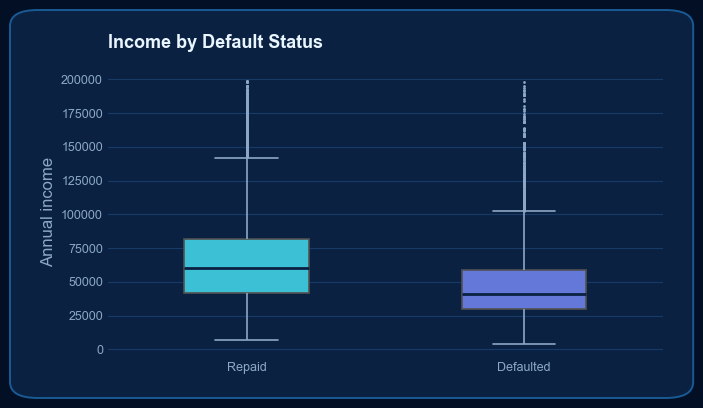

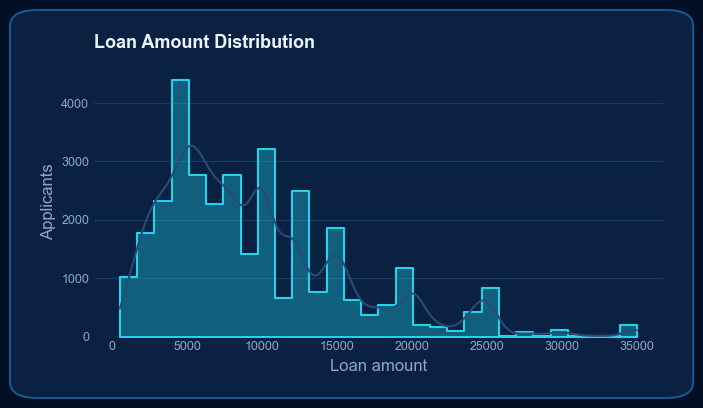

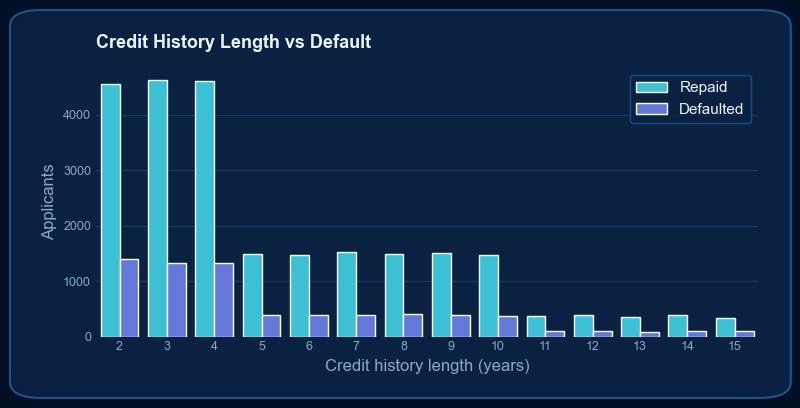

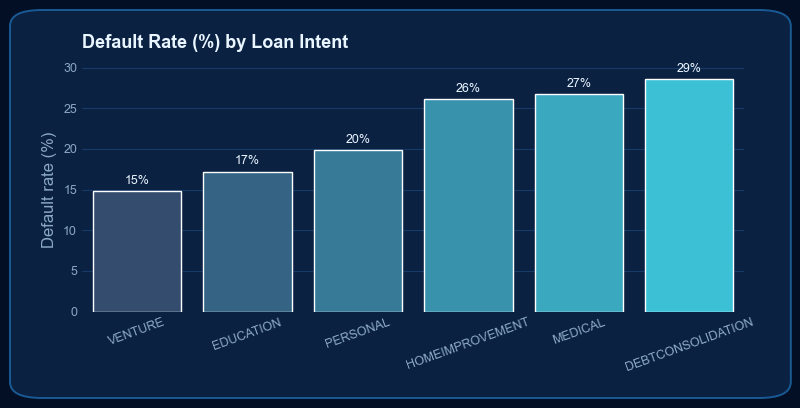

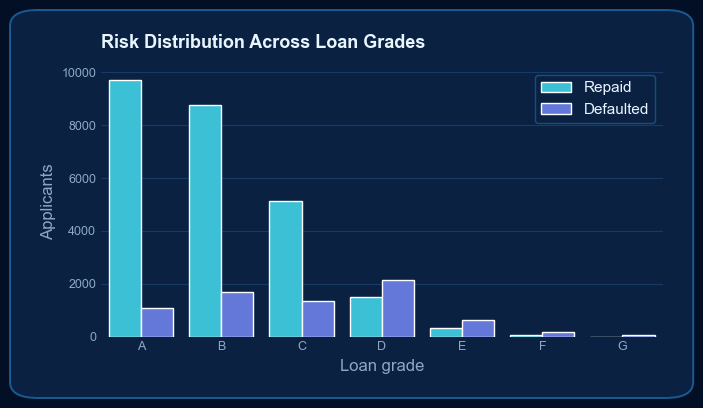

In [10]:
from matplotlib.patches import FancyBboxPatch

os.makedirs("../assets", exist_ok=True)

# ---------- PICK ONE: "dark" | "slate" | "light" ----------
THEME = "dark"

THEMES = {
    # top screenshot: deep navy, glowing cyan
    "dark":  dict(bg="#020F24", panel="#0A2142", edge="#1A5A94",
                  text="#EAF6FF", muted="#8CA8C6", grid="#173A66",
                  a="#22D3EE", b="#4F6BED", c="#2A4A78"),
    # middle screenshot: slate background, white cards
    "slate": dict(bg="#8F9DBB", panel="#F4F7FB", edge="#C9D3E6",
                  text="#1B2A41", muted="#5E6E80", grid="#E1E8F2",
                  a="#14C6C6", b="#2C3A5A", c="#4F6BED"),
    # bottom screenshot: soft lavender background, white cards
    "light": dict(bg="#E9E7F7", panel="#F7FAFD", edge="#D5DCEC",
                  text="#1B2A41", muted="#5E6E80", grid="#E6ECF5",
                  a="#14C6C6", b="#2C3A5A", c="#4F6BED"),
}
T = THEMES[THEME]
A, B, C = T["a"], T["b"], T["c"]          # repaid, defaulted, accent
STATUS_PALETTE = {0: A, 1: B}
STATUS_LABELS = ["Repaid", "Defaulted"]

# All colors go INTO set_theme so nothing overrides them
sns.set_theme(style="white", rc={
    "figure.facecolor": T["bg"], "savefig.facecolor": T["bg"],
    "axes.facecolor": "none", "axes.edgecolor": "none",
    "axes.labelcolor": T["muted"], "text.color": T["text"],
    "xtick.color": T["muted"], "ytick.color": T["muted"],
    "grid.color": T["grid"], "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "legend.facecolor": T["panel"], "legend.edgecolor": T["edge"],
    "legend.labelcolor": T["text"],
})

needed = ["loan_status", "person_income", "loan_amnt",
          "cb_person_cred_hist_length", "loan_intent", "loan_grade"]
missing = [c for c in needed if c not in df.columns]
assert not missing, f"Missing columns: {missing}"


def finish(fig, ax, title, path):
    ax.set_facecolor("none")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold",
                 color=T["text"], pad=14)
    ax.tick_params(length=0, colors=T["muted"], labelsize=9)
    ax.xaxis.label.set_color(T["muted"])
    ax.yaxis.label.set_color(T["muted"])
    ax.grid(axis="y", color=T["grid"], linewidth=0.8)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    leg = ax.get_legend()
    if leg:
        leg.get_frame().set_facecolor(T["panel"])
        leg.get_frame().set_edgecolor(T["edge"])
        for t in leg.get_texts():
            t.set_color(T["text"])

    # rounded card behind everything
    fig.add_artist(FancyBboxPatch(
        (0.012, 0.015), 0.976, 0.97,
        boxstyle="round,pad=0,rounding_size=0.04",
        transform=fig.transFigure, facecolor=T["panel"],
        edgecolor=T["edge"], linewidth=1.4, zorder=-1))
    fig.tight_layout(rect=(0.03, 0.03, 0.97, 0.97))
    fig.savefig(path, dpi=300, facecolor=T["bg"])
    plt.show()


# ---------- 1. Income vs Default ----------
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(
    x="loan_status", y="person_income", hue="loan_status",
    data=df[df["person_income"] < 200000], palette=STATUS_PALETTE,
    legend=False, ax=ax, width=0.45, linewidth=1.2, fliersize=2,
    flierprops=dict(markerfacecolor=T["muted"], markeredgecolor="none"),
    medianprops=dict(color=T["panel"], linewidth=2),
    whiskerprops=dict(color=T["muted"]), capprops=dict(color=T["muted"]),
)
ax.set_xticks([0, 1])
ax.set_xticklabels(STATUS_LABELS)
ax.set_xlabel("")
ax.set_ylabel("Annual income")
finish(fig, ax, "Income by Default Status", "../assets/eda_income_patterns.png")

# ---------- 2. Loan Amount Distribution ----------
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["loan_amnt"], bins=30, kde=True, color=A,
             element="step", alpha=0.35, linewidth=1.5, ax=ax)
ax.lines[0].set_color(C)
ax.set_xlabel("Loan amount")
ax.set_ylabel("Applicants")
finish(fig, ax, "Loan Amount Distribution", "../assets/eda_loan_amounts.png")

# ---------- 3. Credit History vs Default ----------
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(
    x="cb_person_cred_hist_length", hue="loan_status",
    data=df[df["cb_person_cred_hist_length"] <= 15],
    palette=STATUS_PALETTE, ax=ax)
ax.legend(title="", labels=STATUS_LABELS, frameon=True)
ax.set_xlabel("Credit history length (years)")
ax.set_ylabel("Applicants")
finish(fig, ax, "Credit History Length vs Default",
       "../assets/eda_cred_history.png")

# ---------- 4. Default Rate by Loan Intent ----------
default_by_intent = (
    df.groupby("loan_intent")["loan_status"].mean().sort_values() * 100)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=default_by_intent.index, y=default_by_intent.values,
    hue=default_by_intent.index, legend=False,
    palette=sns.blend_palette([C, A], len(default_by_intent)), ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}%",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9, color=T["text"],
                xytext=(0, 3), textcoords="offset points")
plt.setp(ax.get_xticklabels(), rotation=20)
ax.set_xlabel("")
ax.set_ylabel("Default rate (%)")
finish(fig, ax, "Default Rate (%) by Loan Intent",
       "../assets/eda_default_trends_intent.png")

# ---------- 5. Risk Distribution Across Grades ----------
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    x="loan_grade", hue="loan_status", data=df,
    order=sorted(df["loan_grade"].unique()),
    palette=STATUS_PALETTE, ax=ax)
ax.legend(title="", labels=STATUS_LABELS, frameon=True)
ax.set_xlabel("Loan grade")
ax.set_ylabel("Applicants")
finish(fig, ax, "Risk Distribution Across Loan Grades",
       "../assets/eda_risk_distribution_grade.png")

In [5]:
# Convert binary and grade columns
df["cb_person_default_on_file"] = df["cb_person_default_on_file"].map(
    {"Y": 1, "N": 0}
)
grade_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
df["loan_grade"] = df["loan_grade"].map(grade_map)

# One-hot encode remaining categories
df = pd.get_dummies(
    df, columns=["person_home_ownership", "loan_intent"], drop_first=True
)

# Separate features (X) and label (y)
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

# 80% train, 20% test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale features (THIS DEFINES X_train_scaled)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save feature list and scaler into model/
os.makedirs("../model", exist_ok=True)
joblib.dump(list(X.columns), "../model/feature_names.pkl")
joblib.dump(scaler, "../model/scaler.pkl")

print("Cell 3 complete! X_train_scaled is now in memory.")

Cell 3 complete! X_train_scaled is now in memory.


In [6]:
# 1. Baseline Logistic Regression
log_model = LogisticRegression(class_weight="balanced", max_iter=1000)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)
print("=== LOGISTIC REGRESSION ===")
print(classification_report(y_test, y_pred_log))

# 2. Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("\n=== RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf))
print(f"Random Forest ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      5095
           1       0.52      0.79      0.63      1422

    accuracy                           0.80      6517
   macro avg       0.73      0.79      0.75      6517
weighted avg       0.84      0.80      0.81      6517


=== RANDOM FOREST ===
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5095
           1       0.98      0.72      0.83      1422

    accuracy                           0.93      6517
   macro avg       0.95      0.86      0.89      6517
weighted avg       0.94      0.93      0.93      6517

Random Forest ROC-AUC Score: 0.9313


In [7]:
# Save Random Forest model into the model folder
joblib.dump(rf_model, "../model/credit_risk_rf_model.pkl")


# Define decision rules (Module 5)
def generate_recommendation(prob):
    if prob < 0.30:
        return "Approve Loan"
    elif 0.30 <= prob <= 0.60:
        return "Review Manually"
    else:
        return "Reject Application"


# Test on first test row
test_prob = rf_model.predict_proba(X_test.iloc[[0]])[:, 1][0]
print(f"Sample Default Probability: {test_prob:.2f}")
print(f"System Recommendation: {generate_recommendation(test_prob)}")

Sample Default Probability: 0.08
System Recommendation: Approve Loan
